# Chapitre 12 - Exercices 12.6 à 12.11

* 12.6 : *optimal scoring* et problème aux valeurs propres ;
* 12.7 : *optimal scoring* pénalisé (PDA) ;
* 12.8 : les coefficients de l'*optimal scoring* sont proportionnels aux directions de la LDA ;
* 12.9 : LDA sur les valeurs ajustées d'une régression sur indicatrices ;
* 12.10 : LDA régularisée à noyau ;
* 12.11 : un modèle de mélange à centres partagés (MDA2) et son algorithme EM.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch12_svm import (LDA, FDA, MDA, class_indicator, second_diff_penalty, kmeans,
                          rbf_kernel, poly2_features, polynomial_kernel, simulate_mixture,
                          mixture_bayes_prob, plot_mixture_boundary, simulate_waveform)
set_style()

Notations communes : $Y$ est la matrice indicatrice $N\times K$ des classes,
$D_\pi = Y^TY/N = \mathrm{diag}(\hat\pi_1,\dots,\hat\pi_K)$ la matrice des proportions de
classes, $H$ la matrice $N\times M$ des $h_j(x_i)$. Nous utilisons les données *vowel*
(11 classes, 10 variables) pour les vérifications.

In [2]:
Xv, gv = datasets.load_vowel("train")
Yv, cls = class_indicator(gv)
N, K = Yv.shape
Dpi = Yv.T @ Yv / N
Hv = np.column_stack([np.ones(N), Xv])          # base : constante + variables
print("N = %d, K = %d, p = %d" % (N, K, Xv.shape[1]))

N = 528, K = 11, p = 10


## Exercice 12.6 : *Optimal scoring* et valeurs propres

**Énoncé (reformulé).** La régression de la FDA est un développement linéaire sur des
fonctions de base $h_m(x)$, $m = 1,\dots,M$.

(a) Montrer que le problème (12.52) s'écrit $\min_{\theta,\beta}\|Y\theta - H\beta\|^2$ (12.65),
où $\theta\in\mathbb R^K$.
(b) Interpréter les normalisations $\theta^TD_\pi\mathbf 1 = 0$ et $\theta^TD_\pi\theta = 1$.
(c) Montrer qu'après optimisation en $\beta$, on obtient $\max_\theta\theta^TY^TSY\theta$ (12.66)
sous ces contraintes, où $S$ est le projecteur associé à $H$.
(d) Si les $h_j$ contiennent la fonction constante, montrer que la plus grande valeur propre
de $S$ vaut 1.
(e) Avec une matrice $\Theta$ ($K\times K$) de scores normalisée par $\Theta^TD_\pi\Theta = I$,
montrer que la solution de (12.53) est donnée par l'ensemble des vecteurs propres ; le
premier est trivial et assure le centrage, les autres caractérisent la solution.

**(a)** Le score de l'observation $i$ est $\theta(g_i) = \sum_k y_{ik}\theta_k = (Y\theta)_i$
puisque la ligne $i$ de $Y$ ne contient qu'un 1, en colonne $g_i$. La prédiction est
$\sum_m\beta_mh_m(x_i) = (H\beta)_i$. Donc $\sum_i(\theta(g_i) - h(x_i)^T\beta)^2 = \|Y\theta - H\beta\|^2$.

**(b)** $\theta^TD_\pi\mathbf 1 = \sum_k\hat\pi_k\theta_k = \frac1N\sum_i\theta(g_i)$ : les
scores sont **centrés** sur l'échantillon. $\theta^TD_\pi\theta = \frac1N\sum_i\theta(g_i)^2$ :
avec le centrage, c'est la **variance** empirique des scores, fixée à 1. Ces contraintes
excluent la solution triviale $\theta = 0$ (et la solution constante).

**(c)** À $\theta$ fixé, (12.65) est un problème de moindres carrés en $\beta$ : $\hat\beta =
(H^TH)^{-1}H^TY\theta$ et $H\hat\beta = SY\theta$ avec $S = H(H^TH)^{-1}H^T$, projecteur
orthogonal ($S^T = S$, $S^2 = S$). Le résidu vaut

$$\|(I-S)Y\theta\|^2 = \theta^TY^T(I-S)^T(I-S)Y\theta = \theta^TY^T(I-S)Y\theta = N\theta^TD_\pi\theta - \theta^TY^TSY\theta = N - \theta^TY^TSY\theta,$$

en utilisant $(I-S)^T(I-S) = I - S$ et $Y^TY = ND_\pi$. Minimiser le résidu revient donc à
maximiser $\theta^TY^TSY\theta$ sous les contraintes de (b).

**(d)** $S$ est un projecteur : si $Sv = \mu v$ avec $v\ne0$, alors $\mu v = Sv = S^2v = \mu^2v$,
donc $\mu\in\{0, 1\}$. Si la constante est dans l'espace engendré par les colonnes de $H$,
alors $S\mathbf 1 = \mathbf 1$ : 1 est valeur propre, c'est la plus grande.

Version « problème d'optimal scoring » : le quotient $\frac{\theta^TY^TSY\theta}{N\theta^TD_\pi\theta} = \frac{\|SY\theta\|^2}{\|Y\theta\|^2}\le1$
(une projection orthogonale diminue la norme), et il vaut 1 pour $\theta = \mathbf 1$ car
$Y\mathbf 1 = \mathbf 1$ et $S\mathbf 1 = \mathbf 1$. La plus grande valeur propre généralisée de
$(\frac1NY^TSY, D_\pi)$ vaut donc 1, atteinte par les scores constants.

**(e)** Avec $L$ colonnes de scores, (12.53) se réduit de même à maximiser
$\mathrm{tr}(\Theta^TY^TSY\Theta)$ sous $\Theta^TD_\pi\Theta = I$. Posons $\Phi = D_\pi^{1/2}\Theta$ :
la contrainte devient $\Phi^T\Phi = I$ et l'objectif $\mathrm{tr}(\Phi^TA\Phi)$ avec
$A = D_\pi^{-1/2}Y^TSYD_\pi^{-1/2}$ symétrique. Le maximum d'une trace sous contrainte
d'orthonormalité est atteint par les vecteurs propres de $A$ associés aux plus grandes valeurs
propres (théorème de Ky Fan, généralisation du quotient de Rayleigh). Revenant à $\Theta$ : les
colonnes de $\Theta$ sont les vecteurs propres **généralisés**
$Y^TSY\theta = \mu\,ND_\pi\theta$.

* Le premier ($\mu = 1$) est $\theta = \mathbf 1$ (normalisé : $\mathbf 1^TD_\pi\mathbf 1 = 1$) :
  solution triviale.
* Les autres sont $D_\pi$-orthogonaux au premier : $\theta^TD_\pi\mathbf 1 = 0$, c'est-à-dire
  **centrés** - la contrainte (b) est automatiquement satisfaite. Ce sont les scores optimaux.

**Vérification numérique** sur *vowel* avec $H = [\mathbf 1, X]$.

In [3]:
S = Hv @ np.linalg.solve(Hv.T @ Hv, Hv.T)
print("valeurs propres de S dans {0,1} :", np.allclose(np.sort(np.linalg.eigvalsh(S))[-(Hv.shape[1] + 1):].round(8),
                                                     np.r_[0, np.ones(Hv.shape[1])]))
mu, Theta = eigh(Yv.T @ S @ Yv / N, Dpi)
mu, Theta = mu[::-1], Theta[:, ::-1]
print("valeurs propres généralisées :", mu.round(4))
print("premier vecteur propre (constant ?) :", (Theta[:, 0] * np.sign(Theta[0, 0])).round(4))
print("Theta^T Dpi Theta = I :", np.allclose(Theta.T @ Dpi @ Theta, np.eye(K)))
print("scores suivants centrés (theta^T Dpi 1 = 0) :", np.allclose(Theta[:, 1:].T @ Dpi @ np.ones(K), 0))

valeurs propres de S dans {0,1} : True
valeurs propres généralisées : [1.000e+00 8.021e-01 7.174e-01 2.432e-01 1.213e-01 7.140e-02 5.650e-02
 1.830e-02 7.600e-03 1.000e-03 6.000e-04]
premier vecteur propre (constant ?) : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Theta^T Dpi Theta = I : True
scores suivants centrés (theta^T Dpi 1 = 0) : True


Il y a $\min(K-1, p) = 10$ valeurs propres non triviales non nulles ; la dernière est nulle car
$p + 1 = 11 = K$. Vérifions enfin que le résidu moyen vaut bien $1 - \mu_\ell$ pour chaque score :

In [4]:
for l in [1, 2, 3]:
    th = Theta[:, l]
    resid = Yv @ th - S @ Yv @ th
    print("score %d : ASR = %.4f   1 - mu = %.4f" % (l, resid @ resid / N, 1 - mu[l]))

score 1 : ASR = 0.1979   1 - mu = 0.1979
score 2 : ASR = 0.2826   1 - mu = 0.2826
score 3 : ASR = 0.7568   1 - mu = 0.7568


> **À retenir.** L'*optimal scoring* est un problème aux valeurs propres généralisé
> $Y^TSY\theta = \mu ND_\pi\theta$ ; la solution constante ($\mu = 1$) absorbe le centrage.

## Exercice 12.7 : *Optimal scoring* pénalisé

**Énoncé.** Obtenir la solution du problème d'*optimal scoring* pénalisé (12.57) :

$$\min\ \frac1N\sum_{\ell}\left[\sum_i(\theta_\ell(g_i) - h(x_i)^T\beta_\ell)^2 + \lambda\beta_\ell^T\Omega\beta_\ell\right].$$

**Solution.** *Étape 1 : optimisation en $\beta$ à $\theta$ fixé.* Pour un score, le critère
$\|Y\theta - H\beta\|^2 + \lambda\beta^T\Omega\beta$ est quadratique convexe en $\beta$ ; son
gradient $-2H^T(Y\theta - H\beta) + 2\lambda\Omega\beta$ s'annule pour

$$\hat\beta = (H^TH + \lambda\Omega)^{-1}H^TY\theta\qquad\text{(régression ridge généralisée)}.$$

*Étape 2 : valeur du critère.* En notant $A = H^TH + \lambda\Omega$, on développe et on utilise
$A\hat\beta = H^TY\theta$ :

$$\|Y\theta - H\hat\beta\|^2 + \lambda\hat\beta^T\Omega\hat\beta = \theta^TY^TY\theta - 2\hat\beta^TH^TY\theta + \hat\beta^TA\hat\beta = \theta^TY^TY\theta - \theta^TY^TS_\lambda Y\theta,$$

avec $S_\lambda = H(H^TH + \lambda\Omega)^{-1}H^T$ (l'opérateur de lissage, qui n'est plus un
projecteur).

*Étape 3 : scores.* Avec la normalisation $\theta^TD_\pi\theta = 1$, minimiser revient à
maximiser $\theta^TY^TS_\lambda Y\theta$ : les scores optimaux sont les vecteurs propres
généralisés de $(\frac1NY^TS_\lambda Y, D_\pi)$, exactement comme en 12.6(e) avec $S_\lambda$ à
la place de $S$. Si la constante est dans la base et **non pénalisée**, $S_\lambda\mathbf 1 = \mathbf 1$
(le vecteur $\beta = e_1$ vérifie $A e_1 = H^T\mathbf 1$ car $\Omega e_1 = 0$) : la solution
triviale subsiste et les autres scores sont centrés. Enfin $\hat\beta_\ell = A^{-1}H^TY\theta_\ell$.

*Étape 4 : lien avec la PDA.* Séparons la constante et notons $\tilde H$ la matrice des
$h(x_i)$ centrés, $\Sigma_T = \tilde H^T\tilde H/N$, $M$ la matrice $K\times M$ des moyennes de
classes centrées, $\Sigma_B = M^TD_\pi M$ et $\Sigma_W = \Sigma_T - \Sigma_B$. Alors
$\tilde H^TY = NM^TD_\pi$ et $u = \hat\beta = (\Sigma_T + \frac\lambda N\Omega)^{-1}M^TD_\pi\theta$.
L'équation aux valeurs propres $D_\pi M u = \mu D_\pi\theta$ donne $Mu = \mu\theta$, d'où
$\Sigma_Bu = M^TD_\pi Mu = \mu M^TD_\pi\theta = \mu(\Sigma_T + \frac\lambda N\Omega)u$, puis
(avec $\Sigma_T = \Sigma_W + \Sigma_B$)

$$\Sigma_Bu = \frac{\mu}{1-\mu}\left(\Sigma_W + \tfrac\lambda N\Omega\right)u.$$

Les $\hat\beta_\ell$ sont donc les directions de la **PDA** : maximiser $u^T\Sigma_Bu$ sous
$u^T(\Sigma_W + \lambda'\Omega)u = 1$ avec $\lambda' = \lambda/N$ (cf. (12.58)). $\square$

**Vérification** sur *waveform* (21 variables ordonnées), avec la pénalité de rugosité.

In [5]:
Xw, gw = datasets.load_waveform("train")
Nw = len(gw)
Om = second_diff_penalty(21)
lam = 50.0
pda = FDA(lam=lam, Omega=Om).fit(Xw, gw)
Yw, _ = class_indicator(gw)
pi_w = Yw.mean(0)
Xc = Xw - Xw.mean(0)
Mw = (Yw.T @ Xc) / Yw.sum(0)[:, None]
SB = Mw.T @ (pi_w[:, None] * Mw)
ST = Xc.T @ Xc / Nw
vals, U = eigh(SB, ST - SB + lam / Nw * Om)
U = U[:, ::-1]
for l in range(2):
    b = pda.beta_[1:, l]
    print("direction %d : |cos(beta_FDA pénalisée, u_PDA)| = %.8f" % (l + 1, abs(b @ U[:, l]) / np.linalg.norm(b) / np.linalg.norm(U[:, l])))
mu_pda = pda.eigvals_
print("mu/(1-mu) =", (mu_pda / (1 - mu_pda)).round(5), "  valeurs propres PDA =", vals[::-1][:2].round(5))

direction 1 : |cos(beta_FDA pénalisée, u_PDA)| = 1.00000000
direction 2 : |cos(beta_FDA pénalisée, u_PDA)| = 1.00000000
mu/(1-mu) = [1.11345 0.74499]   valeurs propres PDA = [1.11345 0.74499]


> **À retenir.** L'*optimal scoring* pénalisé remplace le projecteur $S$ par le lisseur
> $S_\lambda = H(H^TH+\lambda\Omega)^{-1}H^T$ ; ses coefficients sont les directions
> discriminantes de la LDA pénalisée, de métrique $\Sigma_W + \frac\lambda N\Omega$.

## Exercice 12.8 : *Optimal scoring* et directions de la LDA

**Énoncé.** Montrer que les coefficients $\beta_\ell$ obtenus par *optimal scoring* sont
proportionnels aux directions discriminantes $\nu_\ell$ de la LDA.

**Solution.** C'est le cas $\lambda = 0$, $h(x) = x$ de l'exercice précédent. Reprenons
l'argument sans pénalité. Avec les notations de 12.7, $\beta = \Sigma_T^{-1}M^TD_\pi\theta$ et
l'équation aux valeurs propres donne $M\beta = \mu\theta$, d'où

$$\Sigma_B\beta = M^TD_\pi M\beta = \mu M^TD_\pi\theta = \mu\Sigma_T\beta = \mu(\Sigma_W + \Sigma_B)\beta
\quad\Longrightarrow\quad \Sigma_B\beta = \frac{\mu}{1-\mu}\Sigma_W\beta.$$

Or les directions discriminantes de la LDA (section 4.3.3) sont précisément les vecteurs
propres généralisés $\Sigma_B\nu = \gamma\,\Sigma_W\nu$, rangés par $\gamma$ décroissante. Comme
$\mu\mapsto\mu/(1-\mu)$ est croissante sur $[0,1[$, l'ordre est le même ; pour des valeurs
propres distinctes, les espaces propres sont des droites, donc $\beta_\ell\propto\nu_\ell$.
$\square$

Remarque : $\Sigma_W$ normalisée par $N$ ou par $N - K$ ne change que le facteur de
proportionnalité.

In [6]:
fda_v = FDA().fit(Xv, gv)
lda_v = LDA().fit(Xv, gv)
V, gam = lda_v.canonical_directions()
cosines = [abs(fda_v.beta_[1:, l] @ V[:, l]) / np.linalg.norm(fda_v.beta_[1:, l]) / np.linalg.norm(V[:, l])
           for l in range(fda_v.beta_.shape[1])]
print("|cos(beta_l, nu_l)| pour l = 1..%d :" % len(cosines), np.round(cosines, 8))
mu_v = fda_v.eigvals_
print("mu/(1-mu)                   :", (mu_v / (1 - mu_v))[:4].round(4))
print("gamma (W normalisée par N)  :", (gam[:4] * N / (N - K)).round(4))

|cos(beta_l, nu_l)| pour l = 1..10 : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
mu/(1-mu)                   : [4.052  2.5382 0.3213 0.1381]
gamma (W normalisée par N)  : [4.052  2.5382 0.3213 0.1381]


Les cosinus valent 1 pour les dix directions, et les valeurs propres se correspondent par
$\gamma = \mu/(1-\mu)$ (une fois $W$ normalisée par $N$).

> **À retenir.** Régresser des scores de classes optimaux sur $x$ redonne les directions
> canoniques de Fisher.

## Exercice 12.9 : LDA sur les valeurs ajustées

**Énoncé.** Soit $\hat Y = X\hat B$ la matrice $N\times K$ des valeurs ajustées par la
régression linéaire de la matrice indicatrice sur $X$ ($N\times p$, $p > K$). On considère les
variables réduites $x_i^* = \hat B^Tx_i$. Montrer que la LDA sur les $x_i^*$ est équivalente à
la LDA dans l'espace d'origine.

**Rappel : règle de la LDA.** Avec $\bar\mu$ la moyenne globale et $d_k = \mu_k - \bar\mu$, les
fonctions discriminantes (4.10) s'écrivent, à un terme indépendant de $k$ près,

$$\delta_k(x) = (x - \bar\mu)^TW^{-1}d_k - \tfrac12d_k^TW^{-1}d_k + \log\pi_k .$$

(On développe $x^TW^{-1}\mu_k - \frac12\mu_k^TW^{-1}\mu_k$ avec $\mu_k = \bar\mu + d_k$ ; les
termes $x^TW^{-1}\bar\mu$ et $\bar\mu^TW^{-1}\bar\mu$ ne dépendent pas de $k$.)

**Solution.** *Étape 1 : forme de $\hat B$.* En incluant une constante (ou en centrant), la
partie « pente » de $\hat B$ est $A = \Sigma_T^{-1}M^TD_\pi$ ($p\times K$), avec les notations
de 12.7 : $x^* = c + A^Tx$ où $c$ est un vecteur constant. Les moyennes de classes et la
covariance intra-classe dans l'espace réduit sont donc $\mu_k^* = c + A^T\mu_k$ (donc
$d_k^* = A^Td_k$) et $W^* = A^TWA$.

*Étape 2 : l'image de $A$.* Avec $\Sigma_T = W + M^TD_\pi M$, la formule de
Sherman–Morrison–Woodbury donne
$\Sigma_T^{-1}M^T = W^{-1}M^T(I + D_\pi MW^{-1}M^T)^{-1}$, donc
$A = W^{-1}M^T\,R$ avec $R$ inversible ($K\times K$). Ainsi $\mathrm{Im}(A) = \mathrm{Im}(W^{-1}M^T)$,
qui contient chaque $W^{-1}d_k$.

*Étape 3 : égalité des discriminants.* La matrice $P = A(A^TWA)^+A^TW$ ($^+$ : pseudo-inverse)
est le projecteur $W$-orthogonal sur $\mathrm{Im}(A)$ : il laisse invariant tout vecteur de
$\mathrm{Im}(A)$. Donc $A(A^TWA)^+A^Td_k = P\,W^{-1}d_k = W^{-1}d_k$. Il vient

$$\begin{aligned}
(x^*-\bar\mu^*)^T(W^*)^+d_k^* &= (x-\bar\mu)^TA(A^TWA)^+A^Td_k = (x-\bar\mu)^TW^{-1}d_k,\\
d_k^{*T}(W^*)^+d_k^* &= d_k^TA(A^TWA)^+A^Td_k = d_k^TW^{-1}d_k .
\end{aligned}$$

Les fonctions discriminantes calculées dans l'espace réduit (avec la pseudo-inverse, car
$W^*$ est de rang $K-1$ : les colonnes de $\hat Y$ somment à 1) sont identiques à celles de
l'espace d'origine : mêmes classements. $\square$

In [7]:
Bhat = np.linalg.lstsq(Hv, Yv, rcond=None)[0]            # (p+1) x K, avec constante
Xstar = Hv @ Bhat                                        # = Y chapeau
lda_orig = LDA().fit(Xv, gv)
lda_red = LDA().fit(Xstar, gv)                           # LDA utilise la pseudo-inverse
Xte, gte = datasets.load_vowel("test")
Xte_star = np.column_stack([np.ones(len(gte)), Xte]) @ Bhat
d_orig = lda_orig.decision_function(Xte)
d_red = lda_red.decision_function(Xte_star)
print("rang de W* :", np.linalg.matrix_rank(lda_red.W_), "(K - 1 =", K - 1, ")")
print("écart des discriminants (à une constante près par point) : %.2e"
      % (d_orig - d_red - (d_orig - d_red).mean(1, keepdims=True)).std(1).max())
print("classements identiques sur le test :", np.array_equal(lda_orig.predict(Xte), lda_red.predict(Xte_star)))
print("erreur test LDA = %.3f" % np.mean(lda_orig.predict(Xte) != gte))

rang de W* : 10 (K - 1 = 10 )
écart des discriminants (à une constante près par point) : 6.11e-14
classements identiques sur le test : True
erreur test LDA = 0.556


> **À retenir.** La régression sur indicatrices perd de l'information pour *classer
> directement* (masquage, section 4.2), mais ses valeurs ajustées contiennent toute
> l'information utile à la LDA : elles engendrent le sous-espace discriminant.

## Exercice 12.10 : LDA régularisée à noyau

**Énoncé.** On veut faire une LDA à deux classes sur un vecteur de transformations $h(x)$
de grande dimension, avec une covariance intra-classe régularisée $W_h + \gamma I$. Montrer
que le modèle peut être estimé en utilisant uniquement les produits scalaires
$K(x_i,x_{i'}) = \langle h(x_i), h(x_{i'})\rangle$ : la propriété « noyau » des SVM est
partagée par la LDA régularisée.

**Rappels.** Pour deux classes, la direction discriminante est
$\beta = (W_h + \gamma I)^{-1}(m_2 - m_1)$, où $m_k = \frac1{n_k}\sum_{g_i=k}h(x_i)$ et
$W_h = \frac1N\sum_k\sum_{g_i=k}(h(x_i) - m_k)(h(x_i)-m_k)^T$. On classe selon la projection
$h(x)^T\beta$ comparée à un seuil (milieu des moyennes projetées des deux classes).

**Écriture matricielle.** Soit $H$ la matrice des $h(x_i)^T$ et $\mathbf C = I - E$, où $E$
est la matrice de moyennage par classe ($E_{ii'} = 1/n_k$ si $i,i'$ sont dans la classe $k$,
0 sinon). $\mathbf C$ est un projecteur symétrique (centrage par classe), donc
$W_h = \frac1NH^T\mathbf C^T\mathbf CH = \frac1NH^T\mathbf CH$. Enfin $m_2 - m_1 = H^Td$ avec
$d_i = 1/n_2$ si $g_i = 2$, $-1/n_1$ si $g_i = 1$.

**Solution.** *Étape 1 : $\beta$ est dans l'espace engendré par les $h(x_i)$.* De
$(W_h + \gamma I)\beta = H^Td$ on tire $\beta = \frac1\gamma(H^Td - W_h\beta) = H^T\left(\frac1\gamma\left(d - \frac1N\mathbf CH\beta\right)\right)$,
donc $\beta = H^Ta$ pour un $a\in\mathbb R^N$.

*Étape 2 : équation pour $a$.* En remplaçant $\beta = H^Ta$ :
$(W_h + \gamma I)H^Ta = H^T\left(\frac1N\mathbf CHH^Ta + \gamma a\right) = H^T\left(\frac1N\mathbf C\mathbf Ka + \gamma a\right)$,
avec $\mathbf K = HH^T$. Il suffit donc de résoudre le système $N\times N$

$$\left(\tfrac1N\mathbf C\mathbf K + \gamma I\right)a = d .$$

(Toute solution $a$ fournit $\beta = H^Ta$ solution, et $\beta$ est unique car
$W_h + \gamma I$ est inversible.)

*Étape 3 : projections.* Pour tout $x$, $h(x)^T\beta = \sum_ia_i\langle h(x),h(x_i)\rangle = \sum_ia_iK(x,x_i)$,
et les moyennes projetées des classes s'obtiennent de même. Tout ne dépend que de $K$ : on
peut utiliser un noyau dont le $h$ est de dimension infinie (noyau radial). $\square$

**Vérification 1** : avec le plongement explicite $h$ du noyau $(1 + \langle x,x'\rangle)^2$
(dimension 6), la LDA régularisée « explicite » et sa version noyau donnent les mêmes
projections.

In [8]:
mix = datasets.load_mixture_example()
Xm, gm = mix["x"], mix["y"]

def kernel_lda(Kmat, g, gamma):
    """Coefficients a de la LDA régularisée à noyau (deux classes 0/1)."""
    n = len(g)
    E = np.zeros((n, n))
    for k in (0, 1):
        idx = np.flatnonzero(g == k)
        E[np.ix_(idx, idx)] = 1 / len(idx)
    d = np.where(g == 1, 1 / np.sum(g == 1), -1 / np.sum(g == 0))
    return np.linalg.solve((np.eye(n) - E) @ Kmat / n + gamma * np.eye(n), d)

gamma = 0.1
Hm = poly2_features(Xm)
m1, m2 = Hm[gm == 0].mean(0), Hm[gm == 1].mean(0)
R = Hm - np.where(gm[:, None] == 1, m2, m1)
Wh = R.T @ R / len(gm)
beta_exp = np.linalg.solve(Wh + gamma * np.eye(Hm.shape[1]), m2 - m1)
a = kernel_lda(polynomial_kernel(Xm, Xm, 2), gm, gamma)
Zq = np.random.RandomState(0).randn(5, 2)
print("projections explicites :", (poly2_features(Zq) @ beta_exp).round(6))
print("projections par noyau   :", (polynomial_kernel(Zq, Xm, 2) @ a).round(6))

projections explicites : [ 0.558193  2.552367 -1.322248 -0.197436  0.655466]
projections par noyau   : [ 0.558193  2.552367 -1.322248 -0.197436  0.655466]


**Vérification 2** : LDA régularisée avec le noyau radial ($\gamma_{\text{noyau}} = 1$) sur la
simulation « mixture » ; le seuil est le milieu des moyennes projetées.

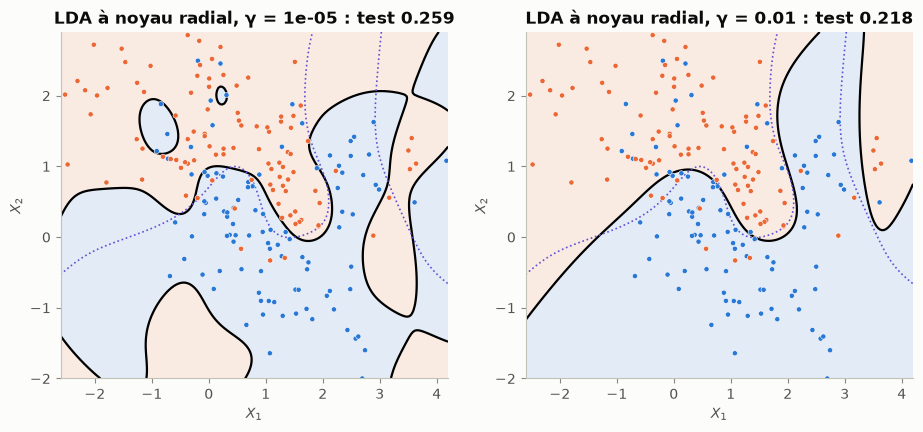

In [9]:
rng = np.random.RandomState(0)
Xmt, gmt = simulate_mixture(5000, mix["means"], rng)
Krbf = rbf_kernel(Xm, Xm, 1.0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, gam_reg in zip(axes, [1e-5, 1e-2]):
    a = kernel_lda(Krbf, gm, gam_reg)
    proj = Krbf @ a
    thr = 0.5 * (proj[gm == 0].mean() + proj[gm == 1].mean())
    fun = lambda Z, a=a, thr=thr: rbf_kernel(Z, Xm, 1.0) @ a - thr
    err = np.mean((fun(Xmt) > 0) != gmt)
    plot_mixture_boundary(ax, Xm, gm, fun, mix["means"],
                          title="LDA à noyau radial, γ = %g : test %.3f" % (gam_reg, err))
plt.show()

Une régularisation trop faible ($\gamma = 10^{-5}$) donne une frontière tortueuse
(sur-apprentissage) ; avec $\gamma = 10^{-2}$, on obtient une frontière proche de celle des
SVM à noyau radial et une erreur test voisine.

> **À retenir.** Dès que la régularisation est en $\|\beta\|^2$ (ici via $\gamma I$), la
> solution vit dans l'espace engendré par les $h(x_i)$ et tout s'exprime avec le noyau : ce
> n'est pas une spécificité des SVM.

## Exercice 12.11 : MDA à centres partagés (MDA2)

**Énoncé (reformulé).** Dans la MDA, chaque centre de mélange appartient à une seule classe.
On considère un modèle plus général où chaque centre est partagé par toutes les classes :

$$P(G,X) = \sum_{r=1}^R\pi_rP_r(G,X)\quad(12.67),\qquad P_r(G,X) = P_r(G)\,\phi(X;\mu_r,\Sigma)\quad(12.68).$$

Chaque région centrée en $\mu_r$ a un « profil de classes » $P_r(G)$. La loi a posteriori est
$P(G=k\mid X=x) = \frac{\sum_r\pi_rP_r(G=k)\phi(x;\mu_r,\Sigma)}{\sum_r\pi_r\phi(x;\mu_r,\Sigma)}$ (12.69).

(a) Montrer que ce modèle (MDA2) généralise la MDA, avec
$P(X\mid G=k) = \sum_r\pi_{rk}\phi(x;\mu_r,\Sigma)$ où
$\pi_{rk} = \pi_rP_r(G=k)/\sum_{r'}\pi_{r'}P_{r'}(G=k)$ (12.70).
(b) Écrire l'algorithme EM pour MDA2.
(c) Montrer que si la matrice de poids initiale est construite comme pour la MDA ($k$-moyennes
séparées dans chaque classe), l'algorithme MDA2 est identique à la MDA.

**(a)** En sommant (12.67) sur $X$ (intégrale de la densité gaussienne égale à 1) :
$P(G=k) = \sum_r\pi_rP_r(G=k)$. Par définition de la probabilité conditionnelle :

$$P(X\mid G=k) = \frac{P(G=k, X)}{P(G=k)} = \frac{\sum_r\pi_rP_r(G=k)\phi(X;\mu_r,\Sigma)}{\sum_{r'}\pi_{r'}P_{r'}(G=k)} = \sum_r\pi_{rk}\phi(X;\mu_r,\Sigma).$$

Les $\pi_{rk}$ sont positifs et somment à 1 sur $r$ : chaque classe est un **mélange
gaussien** de covariance commune, comme dans (12.59), mais les centres $\mu_r$ sont communs à
toutes les classes, seules les proportions changent. La MDA est le cas particulier où
chaque profil $P_r(G)$ est concentré sur une seule classe $k(r)$ : alors $\pi_{rk} = 0$ si
$k\ne k(r)$, et chaque centre n'appartient qu'à une classe.

**(b) Algorithme EM.** On introduit la variable latente $c_i\in\{1,\dots,R\}$ (le centre qui a
engendré l'observation $i$). La log-vraisemblance complète est

$$\ell_c = \sum_i\left[\log\pi_{c_i} + \log P_{c_i}(g_i) + \log\phi(x_i;\mu_{c_i},\Sigma)\right].$$

* **Étape E** : responsabilités
  $w_{ir} = P(c_i = r\mid x_i, g_i) = \dfrac{\pi_rP_r(g_i)\phi(x_i;\mu_r,\Sigma)}{\sum_{r'}\pi_{r'}P_{r'}(g_i)\phi(x_i;\mu_{r'},\Sigma)}$.
* **Étape M** : on maximise $\sum_i\sum_rw_{ir}[\dots]$ ; les trois termes se séparent. Avec
  un multiplicateur de Lagrange pour $\sum_r\pi_r = 1$ (resp. $\sum_kP_r(k) = 1$) :

$$\pi_r = \frac1N\sum_iw_{ir},\qquad P_r(k) = \frac{\sum_{i:g_i=k}w_{ir}}{\sum_iw_{ir}},\qquad \mu_r = \frac{\sum_iw_{ir}x_i}{\sum_iw_{ir}},\qquad \Sigma = \frac1N\sum_i\sum_rw_{ir}(x_i-\mu_r)(x_i-\mu_r)^T.$$

(Pour $\pi_r$ : annuler la dérivée de $\sum_{i,r}w_{ir}\log\pi_r - \nu(\sum_r\pi_r - 1)$ donne
$\pi_r = \sum_iw_{ir}/\nu$ et $\nu = N$ ; même calcul pour $P_r(k)$. Pour $\mu_r$ et $\Sigma$,
ce sont les estimateurs du maximum de vraisemblance gaussiens pondérés.)

**(c)** Supposons qu'à l'initialisation $w_{ir} = 0$ dès que le centre $r$ n'appartient pas à
la classe $g_i$ (poids 0/1 issus de $k$-moyennes dans chaque classe). Montrons par récurrence
que cette propriété est conservée et que les mises à jour coïncident avec celles de la MDA.

* Étape M : $P_r(k) = \sum_{g_i=k}w_{ir}/\sum_iw_{ir}$ vaut 1 si $k = k(r)$ et 0 sinon. Les
  formules de $\mu_r$ et $\Sigma$ sont celles de la MDA. Et
  $\pi_r = \frac1N\sum_{g_i=k(r)}w_{ir} = \frac{N_k}N\cdot\pi_{kr}^{\text{MDA}}$ avec
  $\pi_{kr}^{\text{MDA}} = \sum_{g_i=k}w_{ir}/N_k$.
* Étape E : $P_r(g_i) = 0$ si $k(r)\ne g_i$, donc $w_{ir} = 0$ pour ces centres (propriété
  conservée), et pour les centres de la classe $g_i = k$ :
  $w_{ir} = \frac{\pi_r\phi(x_i;\mu_r,\Sigma)}{\sum_{r':k(r')=k}\pi_{r'}\phi(x_i;\mu_{r'},\Sigma)} = \frac{\pi_{kr}\phi(x_i;\mu_{kr},\Sigma)}{\sum_{\ell}\pi_{k\ell}\phi(x_i;\mu_{k\ell},\Sigma)}$
  (le facteur $N_k/N$ se simplifie), c'est-à-dire (12.62).

Les deux algorithmes produisent donc exactement les mêmes itérés. $\square$

**Mise en œuvre.** Implémentons l'EM de MDA2 et vérifions (c) sur *waveform* ; puis
comparons avec une initialisation « partagée » (poids aléatoires).

In [10]:
def mda2_em(X, g, Winit, n_iter=50):
    """EM pour le modèle MDA2 ; Winit (N, R) : poids initiaux. Renvoie les paramètres."""
    Y, cls_ = class_indicator(g)
    Wt = Winit.copy()
    N_, p = X.shape
    for it in range(n_iter + 1):
        # étape M
        tot = Wt.sum(0)
        pi = tot / N_
        Pr = (Y.T @ Wt) / tot                       # (K, R) : P_r(k)
        mu = (Wt.T @ X) / tot[:, None]
        Sig = sum((Wt[:, r][:, None] * (X - mu[r])).T @ (X - mu[r]) for r in range(len(tot))) / N_
        if it == n_iter:
            break
        # étape E
        Si = np.linalg.inv(Sig)
        q = np.stack([np.einsum("ij,jk,ik->i", X - m, Si, X - m) for m in mu], 1)
        logw = np.log(pi + 1e-300) + np.log(Y @ Pr + 1e-300) - 0.5 * q
        logw -= logw.max(1, keepdims=True)
        Wt = np.exp(logw); Wt /= Wt.sum(1, keepdims=True)
    return dict(pi=pi, Pr=Pr, mu=mu, Sigma=Sig, classes=cls_)

def mda2_predict(model, X):
    """Règle de Bayes (12.69)."""
    Si = np.linalg.inv(model["Sigma"])
    q = np.stack([np.einsum("ij,jk,ik->i", X - m, Si, X - m) for m in model["mu"]], 1)
    lw = np.log(model["pi"] + 1e-300) - 0.5 * q
    w = np.exp(lw - lw.max(1, keepdims=True))
    post = w @ model["Pr"].T                        # (n, K), à normalisation près
    return model["classes"][post.argmax(1)]

Initialisation « à la MDA » : on reproduit exactement les $k$-moyennes utilisées par la classe
`MDA` du module (même générateur aléatoire), avec 3 centres par classe.

In [11]:
Xwt, gwt = datasets.load_waveform("test")
Rk = 3
rng0 = np.random.RandomState(0)
Yw, _ = class_indicator(gw)
W0 = np.zeros((len(gw), 3 * Rk))
for k in range(3):
    idx = np.flatnonzero(Yw[:, k] == 1)
    _, lab = kmeans(Xw[idx], Rk, rng=rng0)
    W0[idx, k * Rk + lab] = 1.0
m2 = mda2_em(Xw, gw, W0, n_iter=30)
m1 = MDA(n_sub=Rk, n_iter=30, rng=np.random.RandomState(0)).fit(Xw, gw)
print("écart max des centres MDA / MDA2 : %.2e" % np.abs(m2["mu"] - m1.mus_.reshape(-1, 21)).max())
print("écart max des covariances        : %.2e" % np.abs(m2["Sigma"] - m1.Sigma_).max())
print("profils P_r(G) (lignes = classes) :\n", m2["Pr"].round(3))
print("classements identiques sur le test :", np.array_equal(mda2_predict(m2, Xwt), m1.predict(Xwt)))

écart max des centres MDA / MDA2 : 3.55e-15
écart max des covariances        : 4.44e-16
profils P_r(G) (lignes = classes) :
 [[1. 1. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 1. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 1. 1.]]
classements identiques sur le test : True


Les profils restent concentrés sur une seule classe : MDA2 initialisée comme la MDA *est* la
MDA. Avec une initialisation **aléatoire** des poids (centres partagés), les profils peuvent
devenir mixtes ; sur *waveform*, cela a du sens : les classes partagent deux à deux une
forme $h_j$.

In [12]:
rng = np.random.RandomState(1)
res = []
for R in [3, 6, 9]:
    W_rand = rng.dirichlet(np.ones(R), size=len(gw))
    mr = mda2_em(Xw, gw, W_rand, n_iter=100)
    res.append((R, np.mean(mda2_predict(mr, Xw) != gw), np.mean(mda2_predict(mr, Xwt) != gwt)))
    if R == 6:
        m_shared = mr
for R, e1, e2 in res:
    print("MDA2, R = %d centres partagés : erreur app. %.3f, test %.3f" % (R, e1, e2))
print("MDA (3 par classe)            : erreur app. %.3f, test %.3f"
      % (np.mean(m1.predict(Xw) != gw), np.mean(m1.predict(Xwt) != gwt)))

MDA2, R = 3 centres partagés : erreur app. 0.153, test 0.208
MDA2, R = 6 centres partagés : erreur app. 0.147, test 0.232
MDA2, R = 9 centres partagés : erreur app. 0.217, test 0.250
MDA (3 par classe)            : erreur app. 0.113, test 0.180


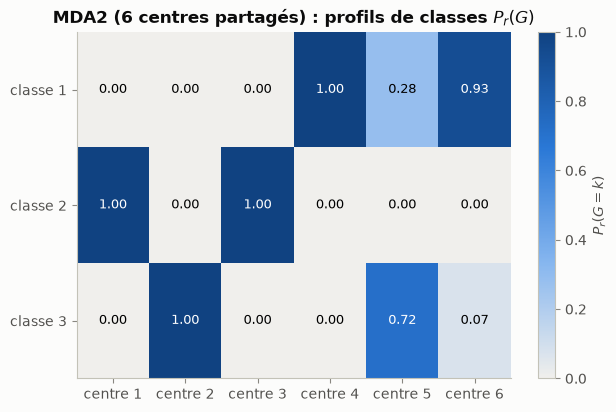

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(m_shared["Pr"], cmap=SEQ, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(6)); ax.set_xticklabels(["centre %d" % (r + 1) for r in range(6)])
ax.set_yticks(range(3)); ax.set_yticklabels(["classe 1", "classe 2", "classe 3"])
for (i, j), v in np.ndenumerate(m_shared["Pr"]):
    ax.text(j, i, "%.2f" % v, ha="center", va="center", fontsize=9, color="k" if v < 0.6 else "white")
ax.grid(False)
ax.set_title("MDA2 (6 centres partagés) : profils de classes $P_r(G)$")
fig.colorbar(im, ax=ax, label="$P_r(G = k)$")
plt.show()

Certains centres se spécialisent d'eux-mêmes (profil concentré sur une classe), d'autres
gardent un profil mixte : ils couvrent une région où deux classes se recouvrent. Sur cet exemple,
le modèle à centres partagés ne fait cependant pas mieux que la MDA : l'EM part ici de poids
aléatoires et peut s'arrêter dans un optimum local, et des centres communs sont moins
adaptés que des centres propres à chaque classe quand les classes sont bien distinctes.

> **À retenir.** MDA2 remplace « des centres par classe » par « des centres communs avec un
> profil de classes » ; l'EM a la même structure, avec en plus la mise à jour des profils
> $P_r(G)$. Initialisé comme la MDA, il reste la MDA, car les zéros des profils sont absorbants.